# 新的 Hypothesis：数学原理与可视化

[H1 时序过滤](#h1) · [H2 运动补偿](#h2)

代码默认折叠，图已执行保存；两张图是构造的原理示意，结果表是单轮真实实验。

**实验约定。** A用于建图，B为另一次独立采集。每项实验中，$M_0$是基线图，$M_1$是干预图；两图由同一份A生成，再冻结，用同一份B、相同AMCL参数与初始化配置评价定位。

$M$在下式中表示地图占据格中心组成的非空点集。点集评分在同一坐标系、膨胀前进行；AMCL使用各组对应的完整栅格图，生成与膨胀规则一致。坐标以米计，展示表将误差换算成cm。空图记为建图失败。

**定位是否改善。** $\hat{\mathbf p}_{m,k}$是在地图$M_m$中估计的机器人二维位置，$\mathbf p_k^*$是同一时刻的真值；$m\in\{0,1\}$。$\mathcal T$为两组都有有效输出的共同评分时间集合：

$$
E_{{\rm loc},m}=
\sqrt{\frac{1}{|\mathcal T|}\sum_{k\in\mathcal T}
\|\hat{\mathbf p}_{m,k}-\mathbf p_k^*\|_2^2}.
$$
直接比较$E_{{\rm loc},1}<E_{{\rm loc},0}$，不再另设差值符号。当前使用预热5秒后的10 Hz时间点，输出滞后不超过0.15秒；不为空的共同时间集才评分。真值只用于事后评分，B评的是定位，尚未测完整导航到达效果。

### Raw基线说明

**Raw的含义。** Raw是本库对“未做地图动态清理的累积基线”的标签，不是一个独立SLAM或定位算法，也不表示完全未经预处理的数据。

| 使用位置 | Raw如何生成 | 后续定位 |
| --- | --- | --- |
| 自写H1 | 用已知起点、轮速里程计和传感器外参，把有效二维回波变到同一坐标系；5 cm栅格至少命中一次就保留，只累计、不回撤，不用H1时序过滤。 | 冻结后用AMCL |
| Practice：SRRG二维对照 | 用SRRG每帧当时估计的传感器位姿直接累计回波；历史累计点不按最终图优化结果重新投影。SRRG输出另含地图维护与图优化。 | 冻结后用AMCL |
| Practice：Raw／DUFOMap／BeautyMap三维对照 | 用受控建图A提供的传感器位姿变换并拼接三维扫描，不调用DUFOMap或BeautyMap清理。该A使用提供的仿真位姿。 | 冻结后用GICP；B不输入真值 |

因此，不同实验的Raw不是同一张图，位姿来源也不相同；只能在各自匹配的对照内比较。SRRG这一组是包含位姿优化与地图维护的端到端对照，不是只改变删除规则的消融。H2基线另称Off，只关闭逐点运动补偿；FAST-LIO实践的Off仍保留LiDAR–IMU估计。

In [1]:
# 公共绘图设置；本格先运行一次
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import font_manager

available = {f.name for f in font_manager.fontManager.ttflist}
font = next((name for name in ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC'] if name in available), 'DejaVu Sans')
plt.rcParams.update({'font.family': font, 'axes.unicode_minus': False,
                     'font.size': 11, 'axes.titlesize': 13, 'figure.dpi': 125,
                     'axes.spines.top': False, 'axes.spines.right': False})
BLUE, ORANGE, PURPLE, GREY = '#2376b7', '#d4782d', '#9756a6', '#7e8b99'

def tidy(ax):
    ax.grid(alpha=.16)
    ax.set_axisbelow(True)

<a id="h1"></a>
## H1｜动态残影清理

**H1：先定义“动态残影清理改善”，再检验规则。**

$S$是A中已观测静态参考位置组成的非空集合，$D$是A中后来被射线验证为空、且不与静态支持或当前障碍物重叠的历史动态位置集合。两组共用相同$S,D$；本轮按10 cm格去重，位姿真值与物体标签只用于构造评分参照，不输入清图算法。

$d(\mathbf q,M)$是参考位置到最近地图点的距离，匹配容差固定为$r=0.15\,\mathrm m$：

$$
d(\mathbf q,M)=\min_{\mathbf x\in M}\|\mathbf q-\mathbf x\|_2.
$$

$$
\mathrm{SA}(M)=\frac{\sum_{\mathbf q\in S}\mathbf1[d(\mathbf q,M)\le r]}{|S|},
\qquad
\mathrm{DA}(M)=\frac{\sum_{\mathbf q\in D}\mathbf1[d(\mathbf q,M)>r]}{|D|}.
$$
公式中的比例取0–1，表格换成百分数。$D$为空时不定义DA；静态对照只看SA。这是二维参考位置的覆盖／未覆盖比例，不是逐个原始点的保留追踪。

**本研究的相对定义：动态残影删除更多，且静态保留相对基线损失不超过1个百分点，才称“动态残影清理改善”。**

$$
\mathrm{DA}(M_1)>\mathrm{DA}(M_0)
\quad\land\quad
\mathrm{SA}(M_1)\ge\mathrm{SA}(M_0)-0.01.
$$
该定义只针对已观测支持上的动态残影；不据此宣称整张地图完整、几何准确或镜面问题已解决。

**实现规则。** $c$为栅格，$\mathbf x_c$为其中心，$b$为0.5秒时间箱。$h(c)$统计至少有一次回波命中的时间箱数，$f(c)$统计至少有一次截断自由射线穿过的时间箱数；每箱各最多计一次，自由射线在回波前15 cm停止：

$$
h(c)=\sum_b\mathbf1[\text{hit in bin }b\text{ at }c],
\qquad
f(c)=\sum_b\mathbf1[\text{free ray in bin }b\text{ through }c].
$$

$$
M_0=\{\mathbf x_c:h(c)>0\},
\qquad
M_1=\{\mathbf x_c:h(c)\ge3\ \land\ h(c)\ge1.5f(c)\}.
$$
这里$M_0$就是本项Raw：已知起点＋轮速里程计位姿累积的5 cm占据格，至少命中一次就保留；有效距离筛选、栅格化与公共膨胀仍然执行。$M_1$仅增加上述时序保留条件。

**要检验的H1：**该规则满足上述清理改善条件，并使$E_{{\rm loc},1}<E_{{\rm loc},0}$。3与1.5是本轮固定的启发式参数；规则本身不是“静态”或“干净”的定义，低命中的静态结构也可能被删。

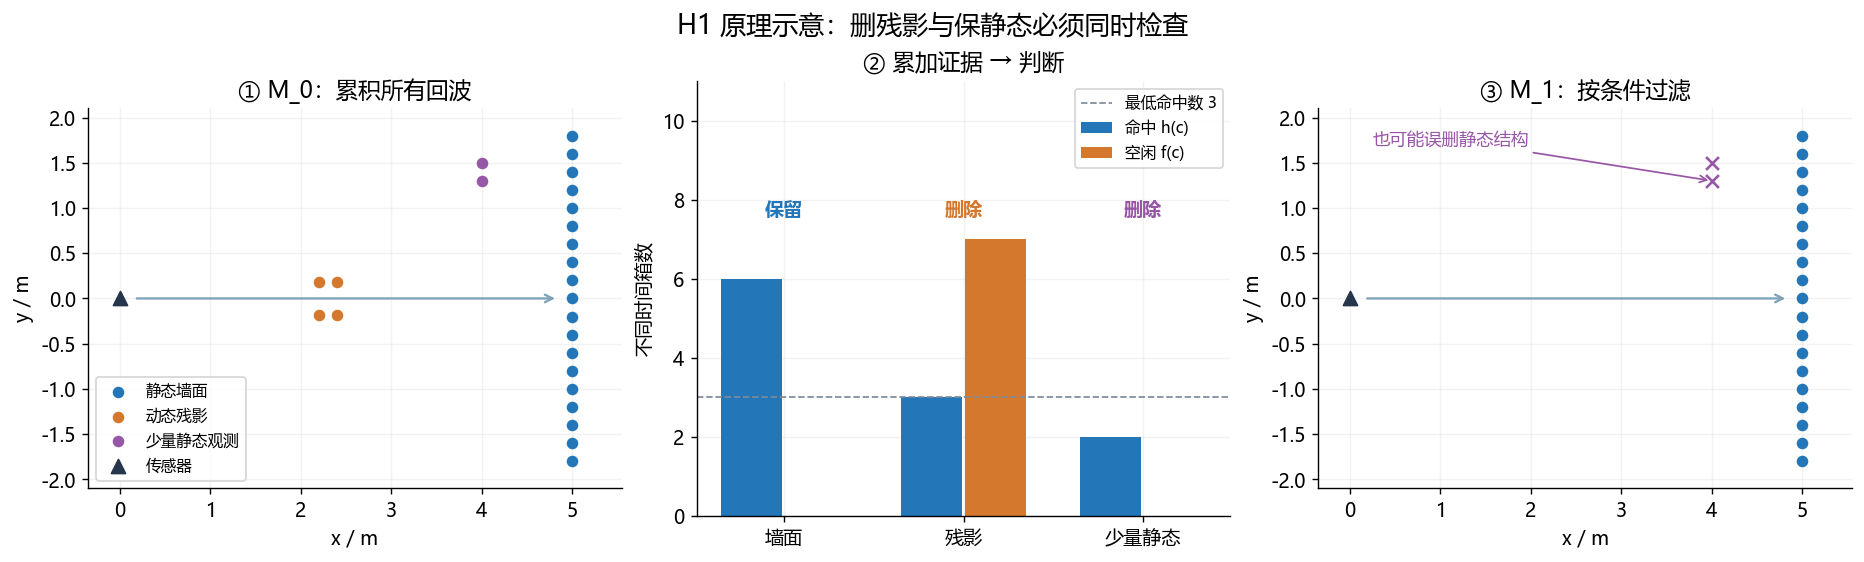

In [2]:
# 可改参数：保留阈值，与当前实现相同
min_hits, free_ratio = 3, 1.5
hits = np.array([6, 3, 2])            # 墙面、动态残影、少量静态观测
free = np.array([0, 7, 0])
keep = (hits >= min_hits) & (hits >= free_ratio * free)  # 对每个栅格应用 M1 的保留条件

wall = np.column_stack([np.full(19, 5.), np.linspace(-1.8, 1.8, 19)])
ghost = np.array([[2.2, -.18], [2.2, .18], [2.4, -.18], [2.4, .18]])
rare = np.array([[4., 1.3], [4., 1.5]])
groups = [wall, ghost, rare]
names = ['静态墙面', '动态残影', '少量静态观测']
colors = [BLUE, ORANGE, PURPLE]

fig, axes = plt.subplots(1, 3, figsize=(14.8, 4.4), layout='constrained')
for i, title in [(0, '① M_0：累积所有回波'), (2, '③ M_1：按条件过滤')]:
    ax = axes[i]
    for points, name, color, retained in zip(groups, names, colors, keep):
        if i == 0 or retained:
            ax.scatter(*points.T, color=color, s=32, label=name, zorder=3)
    ax.scatter(0, 0, color='#26364a', marker='^', s=65, label='传感器')
    ax.annotate('', xy=(4.85, 0), xytext=(.15, 0), arrowprops={'arrowstyle': '->', 'color': '#7da2b8', 'lw': 1.3})
    ax.set(title=title, xlim=(-.35, 5.55), ylim=(-2.1, 2.1), xlabel='x / m', ylabel='y / m')
    ax.set_aspect('equal'); tidy(ax)
axes[0].legend(loc='lower left', fontsize=9)
axes[2].scatter(*rare.T, color=PURPLE, marker='x', s=55)
axes[2].annotate('也可能误删静态结构', xy=rare[0], xytext=(.25, 1.7),
                 color=PURPLE, fontsize=10, arrowprops={'arrowstyle': '->', 'color': PURPLE})

ax = axes[1]
x = np.arange(3)
ax.bar(x-.18, hits, width=.34, color=BLUE, label='命中 h(c)')
ax.bar(x+.18, free, width=.34, color=ORANGE, label='空闲 f(c)')
ax.axhline(min_hits, color=GREY, ls='--', lw=1, label='最低命中数 3')
for i in x:
    ax.text(i, 7.6, '保留' if keep[i] else '删除', ha='center', color=colors[i], weight='bold')
ax.set(xticks=x, xticklabels=['墙面', '残影', '少量静态'], ylim=(0, 11), ylabel='不同时间箱数', title='② 累加证据 → 判断')
ax.legend(loc='upper right', fontsize=9); tidy(ax)
fig.suptitle('H1 原理示意：删残影与保静态必须同时检查', fontsize=15)
plt.show(); plt.close(fig)

**实际实验：动态场景，单轮 A/B。**

**A · 清图比例**

| 方法 | 残影删除 DA ↑ | 静态保留 SA ↑ |
| --- | --- | --- |
| M₀ · Raw：轮速位姿累积 | 5.13% | 99.50% |
| M₁ · Temporal：时序过滤 | 94.87% | 92.55% |

**B · 冻结地图后定位**

| 地图／相同 AMCL | 位置 RMSE / cm ↓ |
| --- | --- |
| M₀ · Raw：轮速位姿累积 | 5.718 |
| M₁ · Temporal：时序过滤 | 6.107 |

本轮残影减少，但静态损失超过 1 个百分点的容差，B 定位未改善，尚不支持 H1。

<a id="h2"></a>
## H2｜统一点的采样参考时刻

**H2：统一采样时刻，再分别检验几何与定位。**

$\mathbf z_i=(x_i,y_i,1)^{\mathsf T}$是在$t_i$采集的传感器局部齐次点；$\hat T(t)\in\mathrm{SE}(2)$为轮式里程计加传感器外参得到的估计变换，从$t$时刻传感器坐标系变到固定地图坐标系。$t_e$为扫描末时刻：

$$
\bar{\mathbf z}_i=\hat T(t_e)^{-1}\hat T(t_i)\mathbf z_i.
$$
先变到固定坐标系，再变回扫描末时刻坐标系。$M_0$不补偿，直接把混合时刻的点当作$t_e$采集；$M_1$先按上式补偿。两图融合时都用$\hat T(t_e)$，其他步骤相同；H2不额外开启H1过滤。

从本项A重新构造静态参照$S$，沿用最近距离$d$，当前几何评分明确定义为：

$$
E_{\rm map}(M)=
\sqrt{\frac1{|M|}\sum_{\mathbf x\in M}d(\mathbf x,S)^2}.
$$
这是“地图到已观测静态支持”的单向距离RMSE，不能单独评价地图完整性；空图判为建图失败，不算几何改善。

**要检验的H2：**

$$
E_{\rm map}(M_1)<E_{\rm map}(M_0)
\quad\land\quad
E_{{\rm loc},1}<E_{{\rm loc},0}.
$$
若只有前一项成立，只支持几何评分改善；不能推断定位改善。当前均为单轮探索，稳定收益仍需重复验证。

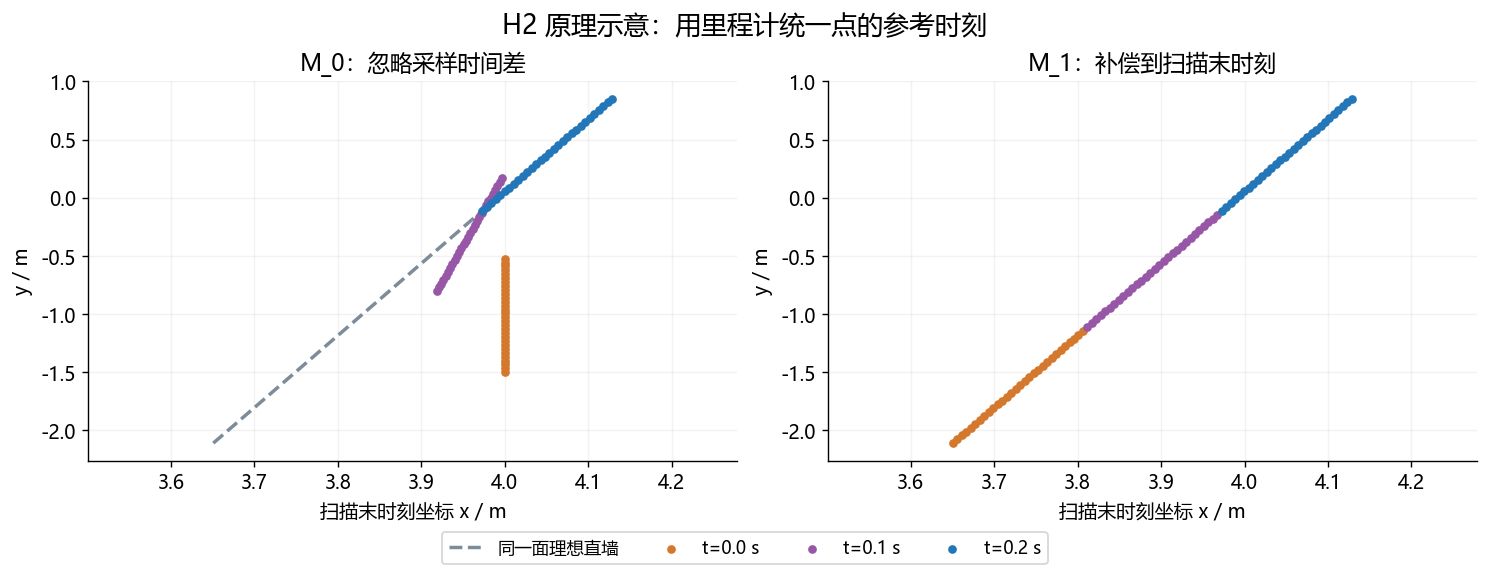

In [3]:
# 可改参数：扫描跨度、角速度、线速度
scan_span, yaw_speed, linear_speed = .2, .8, .3

def T_odom(t):
    angle = yaw_speed * t
    c, s = np.cos(angle), np.sin(angle)
    return np.array([[c, -s, linear_speed*t], [s, c, 0.], [0., 0., 1.]])

def apply_T(T, points):
    return points @ T[:2, :2].T + T[:2, 2]

wall_world = np.column_stack([np.full(90, 4.), np.linspace(-1.5, 1.5, 90)])
times = np.repeat([0., scan_span/2, scan_span], 30)
T_end = T_odom(scan_span)
raw, corrected = np.zeros_like(wall_world), np.zeros_like(wall_world)
for t in np.unique(times):
    mask = times == t
    T_i = T_odom(t)
    raw[mask] = apply_T(np.linalg.inv(T_i), wall_world[mask])
    corrected[mask] = apply_T(np.linalg.inv(T_end) @ T_i, raw[mask])  # 核心公式
reference = apply_T(np.linalg.inv(T_end), wall_world)
np.testing.assert_allclose(corrected, reference, atol=1e-12)

fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.5), layout='constrained')
palette = [ORANGE, PURPLE, BLUE]
for ax, points, title in zip(axes, [raw, corrected], ['M_0：忽略采样时间差', 'M_1：补偿到扫描末时刻']):
    ax.plot(*reference.T, '--', color=GREY, lw=2, label='同一面理想直墙')
    for t, color in zip(np.unique(times), palette):
        mask = times == t
        ax.scatter(*points[mask].T, s=16, color=color, label=f't={t:.1f} s', zorder=3)
    all_points = np.vstack([raw, corrected, reference])
    lo, hi = all_points.min(axis=0)-.15, all_points.max(axis=0)+.15
    ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), xlabel='扫描末时刻坐标 x / m', ylabel='y / m', title=title)
    tidy(ax)
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=4, fontsize=10)
fig.suptitle('H2 原理示意：用里程计统一点的参考时刻', fontsize=15)
plt.show(); plt.close(fig)

**实际实验：运动场景，单轮 A/B。**

**A · 地图几何：E_map 是地图到静态支持的单向距离 RMSE。**

| 方法 | 地图 RMSE / cm ↓ |
| --- | --- |
| M₀：补偿关 | 34.10 |
| M₁：补偿开 | 4.57 |

**B · 冻结地图后定位**

| 地图／相同 AMCL | 位置 RMSE / cm ↓ |
| --- | --- |
| M₀：补偿关 | 4.702 |
| M₁：补偿开 | 4.707 |

本轮只支持建图改善；定位误差未下降。里程计误差、地图结构与匹配条件仍会影响下游定位。

### 实验伪代码

```text
for test, scene in [(H1, static), (H1, dynamic), (H2, motion)]:
    A = acquire_scans_and_wheel_odometry(scene)
    if test == H1:
        h, f = count_time_bins_with_hits_and_free_rays(A, bin_seconds=0.5)
        M0 = cell_centers_where(h > 0)
        M1 = cell_centers_where((h >= 3) & (h >= 1.5 * f))
    else:
        M0 = integrate_A(A, point_compensation=False)
        M1 = integrate_A(A, point_compensation=True)  # no H1 filtering
    freeze(M0, M1)
    B = acquire_independent_scans_and_wheel_odometry(scene)
    positions = {}
    for m, map in [(0, M0), (1, M1)]:
        positions[m] = same_AMCL(B.scans, B.odometry, grid_of(map), same_initial_config)
    # Truth enters only here; references are shared across controls
    S, D = scoring_references_from_A_truth(A)
    if test == H1:
        score_SA(M0, M1, S)
        if scene == dynamic: score_DA(M0, M1, D)
    if test == H2: score_map_RMSE(M0, M1, S)
    score_position_RMSE(positions, B_truth, common_valid_times)
```